# Aulas IA Preditiva Modulo1 Semana 11 Aula2 e Aula3

### Pipeline do Caso: Airbnb

In [1]:
import pandas as pd

pd.set_option('display.width', 110)
pd.set_option('display.max_columns', 10)

bruto = pd.read_csv('dados/brutos/airbnb_rio_bruto.csv')
print(bruto.shape)
bruto[['name', 'host_name', 'neighbourhood_cleansed', 'price', 'minimum_nights', 'last_review']].head(3)



(3060, 25)


,name,host_name,neighbourhood_cleansed,price,minimum_nights,last_review
0,Vaga para mulheres,Anfitrião 1430,Barra da Tijuca,$68.00,1.0,NaN
1,Beautiful apartment on Ipanema beach,Anfitrião 984,Ipanema,"$1,527.50",1.0,2026-09-10
2,Loft em localização na cidade maravilhosa !,Anfitrião 586,Flamengo,$224.00,5.0,2026-05-05


            média  mediana
price  803.333973   446.67


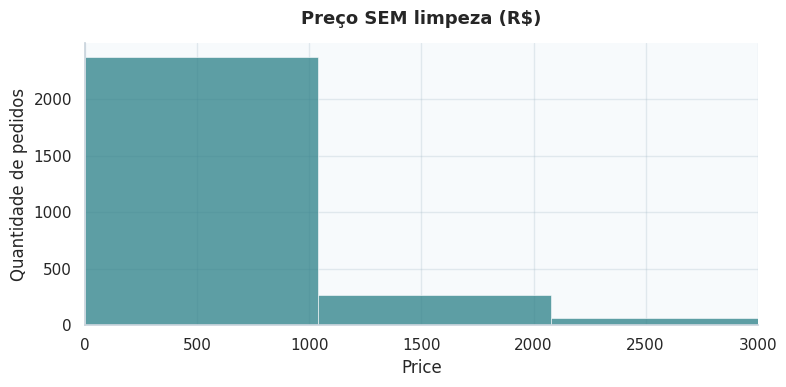

In [2]:
from pipeline_limpeza import Analise, Graficos

sem_limpar = bruto.copy()
sem_limpar['price'] = pd.to_numeric(sem_limpar['price'].str.replace(r'[$,]', '', regex=True), errors='coerce')
print(Analise(sem_limpar).tabela_media_mediana('price'))
Graficos(sem_limpar).histograma('price', 'Preço SEM limpeza (R$)', bins=40, limite=(0, 3000))


In [3]:
from pipeline_limpeza import PipelineLimpeza

pipeline = PipelineLimpeza()
limpo = pipeline.limpar(bruto)
print('linhas:', len(bruto), '->', len(limpo), '| colunas:', limpo.shape[1])


INFO | TratadorAusentes | várias: troquei 0 textos por NaN (linhas removidas: 0)
INFO | TratadorAusentes | neighbourhood_group_cleansed: removi a coluna (linhas removidas: 0)
INFO | TratadorAusentes | host_response_rate: removi a coluna (linhas removidas: 0)
INFO | TratadorAusentes | instant_bookable: removi a coluna (linhas removidas: 0)
INFO | TratadorTipos | price: converti para número (0 valores não convertidos viraram NaN) (linhas removidas: 0)
INFO | TratadorTexto | name: removi espaços extras (linhas removidas: 0)
INFO | TratadorTexto | host_name: removi espaços extras (linhas removidas: 0)
INFO | TratadorTipos | last_review: converti para datetime (errors='coerce') (linhas removidas: 0)
INFO | TratadorUnidades | bathrooms_text: criei 'banheiros' e 'banheiro_compartilhado' (linhas removidas: 0)
INFO | TratadorDuplicados | linha inteira: mantive a primeira ocorrência (linhas removidas: 60)
INFO | TratadorConsistencia | price: 15 valores inválidos viraram NaN (linhas removidas: 0)

linhas: 3060 -> 3000 | colunas: 24


            média  mediana
price  570.658461   447.33


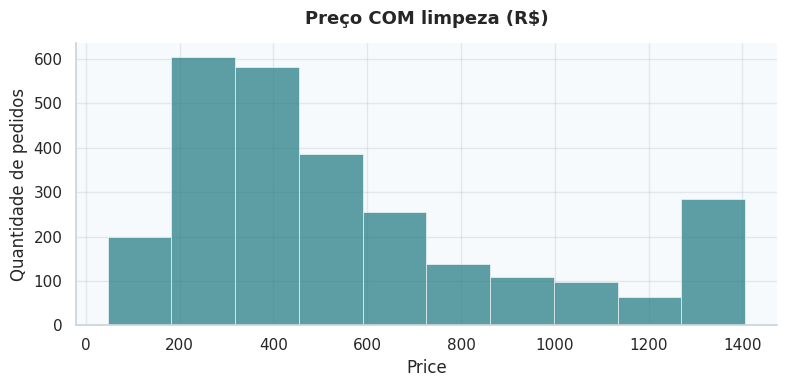

In [7]:
print(Analise(limpo).tabela_media_mediana('price'))
Graficos(limpo).histograma('price', 'Preço COM limpeza (R$)', bins=10)


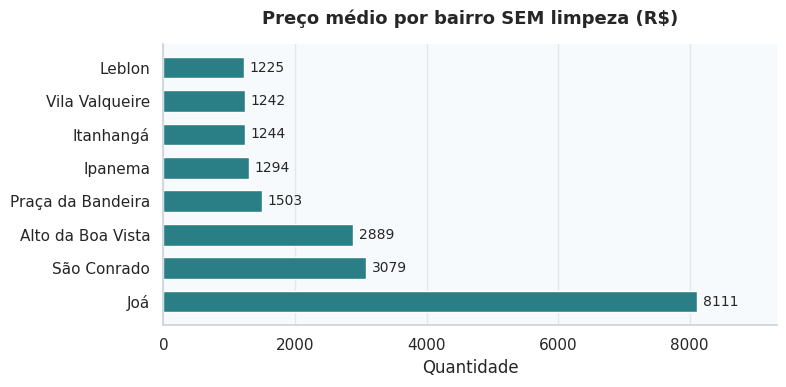

In [8]:
antes_bairro = sem_limpar.groupby('neighbourhood_cleansed')['price'].mean().nlargest(8)
Graficos(sem_limpar).barras_serie(antes_bairro, 'Preço médio por bairro SEM limpeza (R$)', fmt='%.0f', horizontal=True)


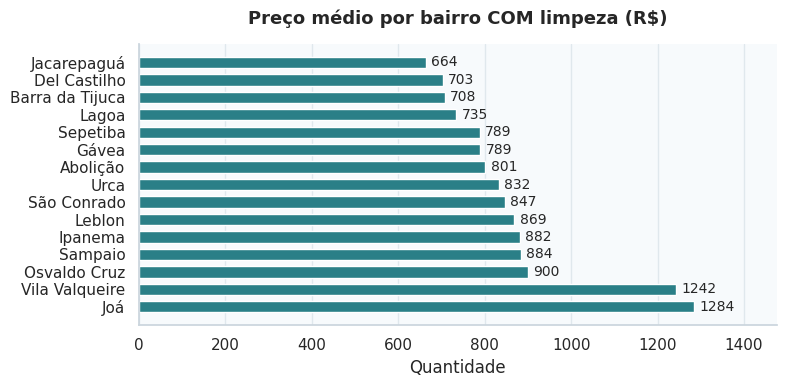

In [11]:
limpos_antes_bairro = limpo.groupby('neighbourhood_cleansed')['price'].mean().nlargest(15)
Graficos(sem_limpar).barras_serie(limpos_antes_bairro, 'Preço médio por bairro COM limpeza (R$)', fmt='%.0f', horizontal=True)

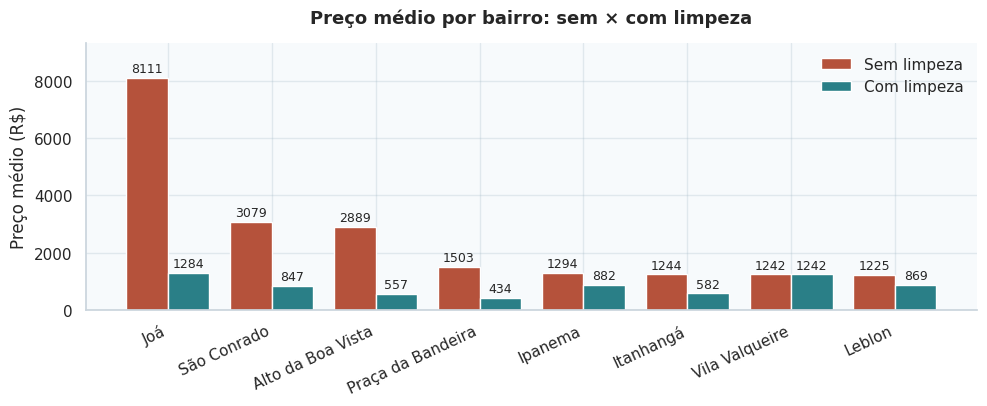

In [10]:
depois_bairro = limpo.groupby('neighbourhood_cleansed')['price'].mean().reindex(antes_bairro.index)
Graficos(limpo).comparar_barras(antes_bairro, depois_bairro, 'Preço médio por bairro: sem × com limpeza', fmt='%.0f')

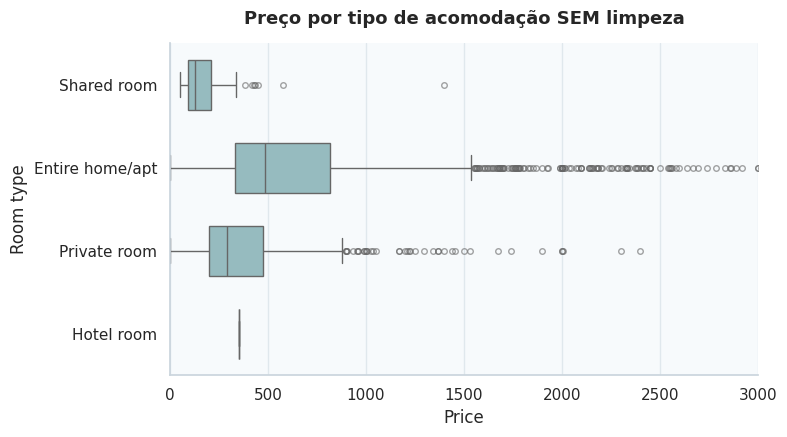

In [12]:
Graficos(sem_limpar).boxplot('price', 'Preço por tipo de acomodação SEM limpeza', grupo='room_type', limite=(0, 3000))


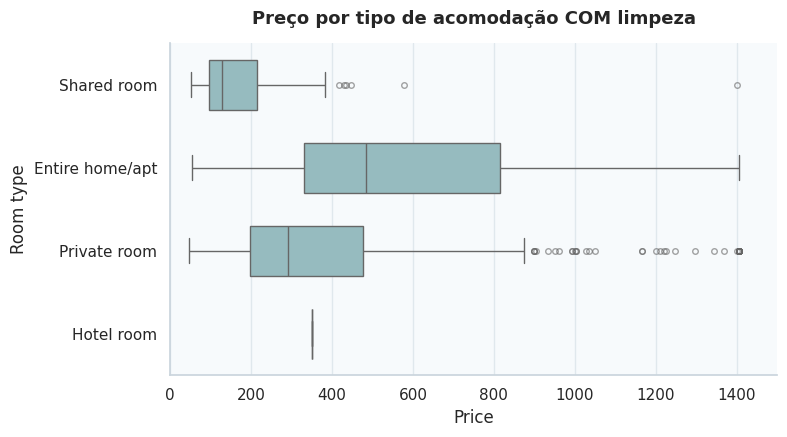

In [15]:
Graficos(limpo).boxplot('price', 'Preço por tipo de acomodação COM limpeza', grupo='room_type', limite=(0, 1500))

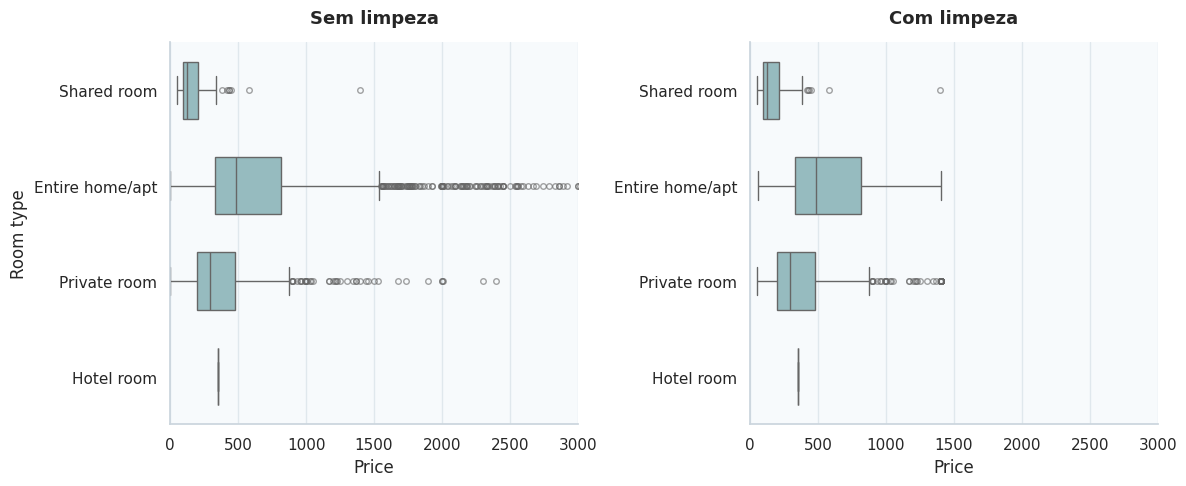

In [16]:
Graficos(limpo).comparar_boxplots(sem_limpar, limpo, 'price', grupo='room_type', limite=(0, 3000))
